# **Лабораторна робота № 11**
**Тема:** Об'єктно-орієнтоване проєктування класів та перевантаження магічних методів.

**Мета:** Опанувати практичні навички об'єктно-орієнтованого аналізу, проектування та реалізації складних програмних моделей мовою Python. Навчитися створювати класи для моделювання інженерних сутностей комп'ютерних систем, реалізовувати інкапсуляцію даних за допомогою механізму приховування атрибутів та дескрипторів властивостей (`@property`, `@setter`), застосовувати механізм наслідування з делегуванням конструктора через `super()`. Опанувати поліморфізм та перевантаження спеціальних методів моделі даних Python (dunder-методів: `__init__`, `__str__`, `__repr__`, `__len__`, `__getitem__`, `__eq__`, `__lt__`, `__add__`) для забезпечення природного математичного та системного синтаксису взаємодії між користувацькими об'єктами.

**Зроблено:** П'ятибрат Дмитро

**Варіант:** 16

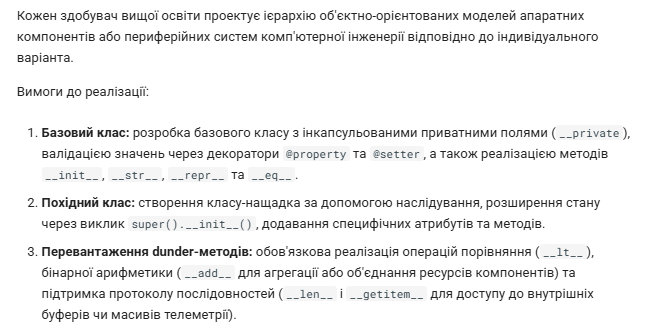

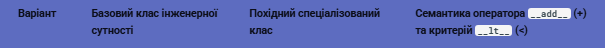
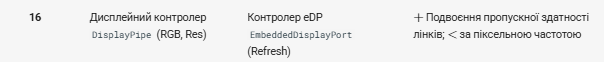
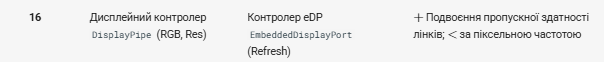

**1. Базовий клас `DisplayPipe` та похідний клас `EmbeddedDisplayPort`**
* **`DisplayPipe`**: інкапсулює приватні атрибути (`__pipe_id`, `__color_depth_bits`, `__resolution`, `__scanline_buffer`), валідує значення через `@property` та `@setter`, реалізує `__init__`, `__str__`, `__repr__`, `__eq__`, а також протокол послідовності (`__len__`, `__getitem__`) для доступу до буфера рядка кадру.
* **`EmbeddedDisplayPort`**: наслідує `DisplayPipe`, розширює стан через `super().__init__()` параметрами частоти оновлення (`refresh_hz`), кількості лінків (`lanes_count`) та швидкості на лінк (`lane_rate_gbps`), обчислює піксельну частоту (МГц) і загальну пропускну здатність лінків (Гбіт/с), перевантажує `__lt__` (за піксельною частотою) та `__add__` (подвоєння пропускної здатності лінків при об'єднанні двох eDP-каналів).

In [1]:
class DisplayPipe:
    """Базовий клас дисплейного конвеєра (RGB, роздільна здатність Res)."""

    ALLOWED_COLOR_DEPTHS = (18, 24, 30, 36)  # біт на піксель (RGB 6/8/10/12 bpc)

    def __init__(
        self,
        pipe_id: str,
        color_depth_bits: int = 24,
        resolution: tuple[int, int] = (1920, 1080),
        scanline_buffer: list[tuple[int, int, int]] | None = None,
    ) -> None:
        self.pipe_id = pipe_id
        self.color_depth_bits = color_depth_bits
        self.resolution = resolution
        if scanline_buffer is None:
            # Спрощений буфер телеметрії/пікселів RGB контрольного рядка
            self.__scanline_buffer = [
                (255, 0, 0),
                (0, 255, 0),
                (0, 0, 255),
                (255, 255, 255),
            ]
        else:
            self.__scanline_buffer = list(scanline_buffer)

    @property
    def pipe_id(self) -> str:
        return self.__pipe_id

    @pipe_id.setter
    def pipe_id(self, value: str) -> None:
        if not isinstance(value, str) or not value.strip():
            raise ValueError("Ідентифікатор дисплейного конвеєра pipe_id має бути непорожнім рядком.")
        self.__pipe_id = value.strip()

    @property
    def color_depth_bits(self) -> int:
        return self.__color_depth_bits

    @color_depth_bits.setter
    def color_depth_bits(self, value: int) -> None:
        if not isinstance(value, int) or value not in self.ALLOWED_COLOR_DEPTHS:
            raise ValueError(
                f"Недопустима глибина кольору RGB: {value} біт. Дозволено: {self.ALLOWED_COLOR_DEPTHS}."
            )
        self.__color_depth_bits = value

    @property
    def resolution(self) -> tuple[int, int]:
        return self.__resolution

    @resolution.setter
    def resolution(self, value: tuple[int, int]) -> None:
        if (
            not isinstance(value, (tuple, list))
            or len(value) != 2
            or not all(isinstance(dim, int) and dim > 0 for dim in value)
        ):
            raise ValueError("Роздільна здатність Res має бути кортежем (width, height) з додатних цілих чисел.")
        self.__resolution = (value[0], value[1])

    @property
    def total_pixels(self) -> int:
        return self.__resolution[0] * self.__resolution[1]

    def __len__(self) -> int:
        """Повертає кількість пікселів у внутрішньому рядковому буфері конвеєра."""
        return len(self.__scanline_buffer)

    def __getitem__(self, index: int | slice) -> tuple[int, int, int] | list[tuple[int, int, int]]:
        """Забезпечує індексований доступ та зрізи до RGB-буфера рядка."""
        return self.__scanline_buffer[index]

    def __eq__(self, other: object) -> bool:
        if not isinstance(other, DisplayPipe):
            return NotImplemented
        return (
            self.__color_depth_bits == other.__color_depth_bits
            and self.__resolution == other.__resolution
        )

    def __str__(self) -> str:
        w, h = self.__resolution
        return f"DisplayPipe[{self.__pipe_id}]: Res={w}x{h}, RGB={self.__color_depth_bits}-bit, buf={len(self)} px"

    def __repr__(self) -> str:
        return (
            f"DisplayPipe(pipe_id={self.__pipe_id!r}, "
            f"color_depth_bits={self.__color_depth_bits!r}, "
            f"resolution={self.__resolution!r})"
        )


class EmbeddedDisplayPort(DisplayPipe):
    """Похідний спеціалізований клас контролера eDP (Embedded DisplayPort)."""

    BLANKING_OVERHEAD = 1.08  # 8% службових інтервалів гасіння (reduced blanking eDP)

    def __init__(
        self,
        pipe_id: str,
        color_depth_bits: int = 24,
        resolution: tuple[int, int] = (1920, 1080),
        refresh_hz: float = 60.0,
        lanes_count: int = 2,
        lane_rate_gbps: float = 2.7,
        scanline_buffer: list[tuple[int, int, int]] | None = None,
    ) -> None:
        super().__init__(
            pipe_id=pipe_id,
            color_depth_bits=color_depth_bits,
            resolution=resolution,
            scanline_buffer=scanline_buffer,
        )
        self.refresh_hz = refresh_hz
        self.lanes_count = lanes_count
        self.lane_rate_gbps = lane_rate_gbps

    @property
    def refresh_hz(self) -> float:
        return self.__refresh_hz

    @refresh_hz.setter
    def refresh_hz(self, value: float) -> None:
        if not isinstance(value, (int, float)) or not (24.0 <= float(value) <= 480.0):
            raise ValueError(f"Частота оновлення Refresh ({value} Гц) має бути в межах 24..480 Гц.")
        self.__refresh_hz = float(value)

    @property
    def lanes_count(self) -> int:
        return self.__lanes_count

    @lanes_count.setter
    def lanes_count(self, value: int) -> None:
        if not isinstance(value, int) or value not in (1, 2, 4, 8):
            raise ValueError(f"Кількість лінків eDP ({value}) має належати набору {{1, 2, 4, 8}}.")
        self.__lanes_count = value

    @property
    def lane_rate_gbps(self) -> float:
        return self.__lane_rate_gbps

    @lane_rate_gbps.setter
    def lane_rate_gbps(self, value: float) -> None:
        if not isinstance(value, (int, float)) or float(value) <= 0:
            raise ValueError("Швидкість одного лінка eDP має бути додатною величиною (Гбіт/с).")
        self.__lane_rate_gbps = float(value)

    @property
    def pixel_clock_mhz(self) -> float:
        """Обчислює піксельну частоту (МГц) з урахуванням ширини, висоти, частоти кадрів та гасіння."""
        return (self.total_pixels * self.__refresh_hz * self.BLANKING_OVERHEAD) / 1_000_000.0

    @property
    def link_bandwidth_gbps(self) -> float:
        """Загальна пропускна здатність лінків eDP (Гбіт/с)."""
        return round(self.__lanes_count * self.__lane_rate_gbps, 3)

    def link_status_report(self) -> str:
        """Спеціалізований метод діагностики інтерфейсу eDP."""
        required_gbps = (self.pixel_clock_mhz * self.color_depth_bits) / 1000.0
        margin = self.link_bandwidth_gbps - required_gbps
        return (
            f"[{self.pipe_id}] PixelClock={self.pixel_clock_mhz:.2f} МГц | "
            f"LinkBW={self.link_bandwidth_gbps:.2f} Гбіт/с ({self.__lanes_count}x{self.__lane_rate_gbps} Гбіт/с) | "
            f"Запас={margin:+.2f} Гбіт/с"
        )

    def __eq__(self, other: object) -> bool:
        if not isinstance(other, EmbeddedDisplayPort):
            return super().__eq__(other)
        return (
            super().__eq__(other)
            and self.__refresh_hz == other.__refresh_hz
            and self.link_bandwidth_gbps == other.link_bandwidth_gbps
        )

    def __lt__(self, other: object) -> bool:
        """Порівняння контролерів eDP (<) за піксельною частотою (МГц)."""
        if not isinstance(other, EmbeddedDisplayPort):
            return NotImplemented
        return self.pixel_clock_mhz < other.pixel_clock_mhz

    def __add__(self, other: object) -> "EmbeddedDisplayPort":
        """
        Оператор '+' (__add__): об'єднання двох контролерів eDP із подвоєнням
        пропускної здатності лінків (агрегація лінків / Dual-Link eDP).
        """
        if not isinstance(other, EmbeddedDisplayPort):
            return NotImplemented

        combined_lanes = min(8, self.__lanes_count + other.__lanes_count)
        effective_lane_rate = max(self.__lane_rate_gbps, other.__lane_rate_gbps)
        if combined_lanes == self.__lanes_count:
            # Якщо досягнуто максимум лінків (8), подвоюємо швидкість лінка
            effective_lane_rate = self.__lane_rate_gbps * 2.0

        merged_buffer = list(self[:]) + list(other[:])
        return EmbeddedDisplayPort(
            pipe_id=f"{self.pipe_id}+{other.pipe_id}",
            color_depth_bits=max(self.color_depth_bits, other.color_depth_bits),
            resolution=max(self.resolution, other.resolution, key=lambda r: r[0] * r[1]),
            refresh_hz=max(self.refresh_hz, other.refresh_hz),
            lanes_count=combined_lanes,
            lane_rate_gbps=effective_lane_rate,
            scanline_buffer=merged_buffer,
        )

    def __str__(self) -> str:
        w, h = self.resolution
        return (
            f"eDP[{self.pipe_id}]: {w}x{h}@{self.__refresh_hz:.0f}Hz, "
            f"RGB={self.color_depth_bits}-bit, PClk={self.pixel_clock_mhz:.2f} МГц, "
            f"BW={self.link_bandwidth_gbps:.2f} Гбіт/с ({self.__lanes_count} lanes)"
        )

    def __repr__(self) -> str:
        return (
            f"EmbeddedDisplayPort(pipe_id={self.pipe_id!r}, color_depth_bits={self.color_depth_bits!r}, "
            f"resolution={self.resolution!r}, refresh_hz={self.__refresh_hz!r}, "
            f"lanes_count={self.__lanes_count!r}, lane_rate_gbps={self.__lane_rate_gbps!r})"
        )

print("Класи DisplayPipe та EmbeddedDisplayPort успішно визначено.")


Класи DisplayPipe та EmbeddedDisplayPort успішно визначено.


**2. Тестування інкапсуляції (`@property`, name mangling), протоколу послідовностей та перевантаження операторів (`+`, `<`, `==`)**

In [2]:
# 1. Створення базового та спеціалізованих контролерів eDP
base_pipe = DisplayPipe("PIPE-A", color_depth_bits=24, resolution=(1920, 1080))
edp_fhd = EmbeddedDisplayPort("eDP-0", color_depth_bits=24, resolution=(1920, 1080), refresh_hz=60, lanes_count=2, lane_rate_gbps=2.7)
edp_qhd = EmbeddedDisplayPort("eDP-1", color_depth_bits=30, resolution=(2560, 1440), refresh_hz=120, lanes_count=2, lane_rate_gbps=5.4)
edp_4k = EmbeddedDisplayPort("eDP-2", color_depth_bits=30, resolution=(3840, 2160), refresh_hz=60, lanes_count=4, lane_rate_gbps=5.4)

print("=== 1. Представлення об'єктів (__str__ та __repr__) ===")
print("str(base_pipe) :", str(base_pipe))
print("repr(base_pipe):", repr(base_pipe))
print("str(edp_fhd)   :", str(edp_fhd))
print("repr(edp_fhd)  :", repr(edp_fhd))

print("\n=== 2. Перевірка інкапсуляції, @setter валідації та Name Mangling ===")
try:
    edp_fhd.refresh_hz = 1000.0  # некоректне значення
except ValueError as err:
    print("Сетер заблокував некоректний стан:", err)

print("Прямий доступ edp_fhd.__refresh_hz доступний?:", hasattr(edp_fhd, "__refresh_hz"))
print("Спотворене ім'я _EmbeddedDisplayPort__refresh_hz:", edp_fhd._EmbeddedDisplayPort__refresh_hz)

print("\n=== 3. Протокол послідовності (__len__ та __getitem__) ===")
print(f"Довжина буфера рядка {edp_fhd.pipe_id}: len() = {len(edp_fhd)} пікселів")
print(f"Перший піксель [0]: {edp_fhd[0]}, зріз [1:3]: {edp_fhd[1:3]}")

print("\n=== 4. Поліморфне сортування за піксельною частотою (__lt__) ===")
controllers = [edp_4k, edp_fhd, edp_qhd]
for ctrl in sorted(controllers):
    print(" ", ctrl.link_status_report())

print("\n=== 5. Агрегація каналів eDP через оператор '+' (__add__) ===")
edp_pair_a = EmbeddedDisplayPort("eDP-L", color_depth_bits=24, resolution=(2560, 1440), refresh_hz=144, lanes_count=2, lane_rate_gbps=5.4)
edp_pair_b = EmbeddedDisplayPort("eDP-R", color_depth_bits=24, resolution=(2560, 1440), refresh_hz=144, lanes_count=2, lane_rate_gbps=5.4)
edp_dual = edp_pair_a + edp_pair_b

print("Лівий канал :", edp_pair_a)
print("Правий канал:", edp_pair_b)
print("Об'єднаний  :", edp_dual)
print(
    f"Перевірка подвоєння пропускної здатності: "
    f"{edp_pair_a.link_bandwidth_gbps:.2f} Гбіт/с -> {edp_dual.link_bandwidth_gbps:.2f} Гбіт/с "
    f"(коефіцієнт = {edp_dual.link_bandwidth_gbps / edp_pair_a.link_bandwidth_gbps:.2f}x)"
)
print(f"Довжина об'єднаного буфера: len(edp_dual) = {len(edp_dual)} пікселів")

print("\n=== 6. Перевірка рівності (__eq__) та NotImplemented при несумісних типах ===")
edp_clone = EmbeddedDisplayPort("eDP-CLONE", color_depth_bits=24, resolution=(1920, 1080), refresh_hz=60, lanes_count=2, lane_rate_gbps=2.7)
print("edp_fhd == edp_clone:", edp_fhd == edp_clone)
print("edp_fhd.__add__(123):", edp_fhd.__add__(123))


=== 1. Представлення об'єктів (__str__ та __repr__) ===
str(base_pipe) : DisplayPipe[PIPE-A]: Res=1920x1080, RGB=24-bit, buf=4 px
repr(base_pipe): DisplayPipe(pipe_id='PIPE-A', color_depth_bits=24, resolution=(1920, 1080))
str(edp_fhd)   : eDP[eDP-0]: 1920x1080@60Hz, RGB=24-bit, PClk=134.37 МГц, BW=5.40 Гбіт/с (2 lanes)
repr(edp_fhd)  : EmbeddedDisplayPort(pipe_id='eDP-0', color_depth_bits=24, resolution=(1920, 1080), refresh_hz=60.0, lanes_count=2, lane_rate_gbps=2.7)

=== 2. Перевірка інкапсуляції, @setter валідації та Name Mangling ===
Сетер заблокував некоректний стан: Частота оновлення Refresh (1000.0 Гц) має бути в межах 24..480 Гц.
Прямий доступ edp_fhd.__refresh_hz доступний?: False
Спотворене ім'я _EmbeddedDisplayPort__refresh_hz: 60.0

=== 3. Протокол послідовності (__len__ та __getitem__) ===
Довжина буфера рядка eDP-0: len() = 4 пікселів
Перший піксель [0]: (255, 0, 0), зріз [1:3]: [(0, 255, 0), (0, 0, 255)]

=== 4. Поліморфне сортування за піксельною частотою (__lt__) ===


### **Висновки**

1. **Переваги парадигми ООП:** Ієрархія класів `DisplayPipe` → `EmbeddedDisplayPort` із делегуванням через `super().__init__()` дозволяє уникнути дублювання коду базового дисплейного конвеєра, ізолювати інженерну логіку обчислення піксельної частоти та пропускної здатності лінків і легко розширювати модель під конкретні стандарти інтерфейсів.
2. **Роль dunder-методів у виразності коду:** Перевантаження `__str__`, `__repr__`, `__eq__`, `__lt__`, `__add__`, `__len__` і `__getitem__` інтегрує користувацькі апаратні об'єкти у стандартні конструкції Python (`print()`, `sorted()`, індексація `obj[i]`, порівняння `==` та `<`, агрегація `a + b`), роблячи код компактним і природним.
3. **Ефективність `@property` та інкапсуляції:** Приховування внутрішніх атрибутів (`__private`) у поєднанні з валідацією в `@setter` гарантує підтримку інваріантів об'єкта (допустимої глибини кольору RGB, коректної роздільної здатності, частоти оновлення та кількості лінків eDP) на всіх етапах життєвого циклу.

### **Контрольні запитання**

1. **Як влаштований механізм спотворення імен (name mangling) у CPython? Чому приватний атрибут __sampling_rate_hz недоступний як obj.__sampling_rate_hz, але доступний через obj._SignalProcessorUnit__sampling_rate_hz?**
Під час компіляції байт-коду CPython автоматично перетворює будь-який ідентифікатор усередині класу, що починається щонайменше з двох підкреслень і закінчується не більше ніж одним підкресленням (наприклад, `__sampling_rate_hz`), на `_ClassName__sampling_rate_hz`. Це робиться для запобігання випадковим колізіям імен атрибутів між базовим і похідними класами при наслідуванні.

2. **Поясніть принципову різницю між спеціальними методами __str__() та __repr__(). У яких системних ситуаціях інтерпретатор автоматично викликає __repr__ замість __str__?**
`__str__()` формує зручне, читабельне подання об'єкта для кінцевого користувача (викликається функціями `str()`, `print()`, у f-рядках без специфікатора `!r`), тоді як `__repr__()` призначений для розробника й налагодження (бажано повертати валідний вираз Python, що відтворює об'єкт). Інтерпретатор викликає `__repr__()` при виведенні елементів усередині стандартних контейнерів (`list`, `tuple`, `dict`, `set`), в інтерактивній консолі REPL, при використанні `!r` у форматуванні, а також як запасний варіант, якщо `__str__()` у класі не визначено.

3. **Опишіть роботу протоколу дескрипторів, що лежить в основі декораторів @property та @setter. Яким чином сетер властивості запобігає переходу об'єкта в некоректний стан?**
Декоратор `@property` створює об'єкт-дескриптор даних (data descriptor), який реалізує методи `__get__`, `__set__` та `__delete__` на рівні класу. Оскільки дескриптор даних має вищий пріоритет пошуку атрибутів, ніж словник екземпляра `obj.__dict__`, будь-яке присвоєння `obj.attr = val` перехоплюється методом `__set__`, який викликає функцію-сетер. Усередині сетера виконується перевірка типів і фізичних меж значення до запису у внутрішнє поле: при порушенні обмежень збуджується виняток (`ValueError`/`TypeError`), і попередній коректний стан об'єкта залишається незмінним.

4. **У чому полягає роль функції super() при наслідуванні класів? Чому при множинному наслідуванні виклик super() є обов'язковим для дотримання лінеаризації MRO за алгоритмом C3?**
`super()` повертає проксі-об'єкт, який делегує виклик методу наступному класу в ланцюжку **MRO** (Method Resolution Order) поточного екземпляра, а не жорстко закодованому батьківському класу. При множинному наслідуванні (особливо у ромбоподібних ієрархіях) порядок обходу класів визначається лінеаризацією C3; прямі виклики `ParentClass.__init__(self)` можуть призвести до повторного виклику спільного базового конструктора або пропуску одного з класів, тоді як кооперативний виклик `super()` гарантує, що кожен клас із MRO буде ініціалізований рівно один раз у правильному порядку.

5. **Що повинна повертати функція перевантаження арифметичного оператора __add__(self, other), якщо переданий операнд other має непідтримуваний тип, і як віртуальна машина PVM обробляє значення NotImplemented?**
Якщо тип `other` не підтримується, метод `__add__` повинен повертати спеціальне вбудоване значення-одинак `NotImplemented` (а не збуджувати `TypeError`). Отримавши `NotImplemented` від `a.__add__(b)`, віртуальна машина Python (PVM) намагається виконати зворотну операцію `b.__radd__(a)`, щоб дати правому операнду шанс обробити додавання; якщо й він повертає `NotImplemented`, PVM самостійно генерує стандартний виняток `TypeError: unsupported operand type(s) for +`.

6. **Розкрийте концепцію качиної типізації (Duck Typing) у контексті поліморфізму Python. Чому функція sorted() здатна впорядковувати список користувацьких об'єктів без явної реалізації спеціальних інтерфейсів?**
Качина типізація означає, що придатність об'єкта до певної операції визначається наявністю у нього потрібних методів і поведінки під час виконання, а не належністю до певного базового класу чи формального інтерфейсу. Алгоритм сортування Timsort у функції `sorted()` під час порівняння елементів використовує оператор `<`, який викликає спеціальний метод `__lt__`; тому будь-який клас, що реалізує `__lt__`, автоматично підтримує сортування через `sorted()` без успадкування від спеціальних класів порівняння.